# Curvas de entrenamiento de la validación cruzada de 5 folds (1000 casos)

Extracción, a partir de los registros de entrenamiento de nnU-Net (`training_log_*.txt`), de los datos por época de las **10 ejecuciones** del experimento principal (baseline y v1, folds 0-4, Dataset503_ImageCAS1000, 100 épocas) y generación de las figuras equivalentes a las del notebook 16 de la fase piloto.

**Entradas:** `TFM_nnUNet/nnUNet_results/Dataset503_ImageCAS1000/<trainer>__nnUNetPlans__3d_fullres/fold_<k>/training_log_*.txt`

**Salidas (en `TFM_nnUNet/`):**
- `curvas_5folds_datos_por_epoca.csv`: una fila por (configuración, fold, época).
- `curvas_5folds_media_sd.png`: curvas medias ± desviación típica entre folds (baseline frente a v1).
- `curvas_5folds_por_fold.png`: pseudo-Dice y pérdida de validación de cada fold por separado.
- `curvas_5folds_resumen.csv`: resumen numérico por configuración y fold (pseudo-Dice final y tiempo de entrenamiento).

No requiere GPU: solo lee ficheros de texto pequeños de Drive.


In [1]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


## 1. Configuración


In [2]:
import re, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path("/content/drive/MyDrive/TFM_nnUNet")
RES = BASE / "nnUNet_results" / "Dataset503_ImageCAS1000"
CONFIG = "nnUNetPlans__3d_fullres"
TRAINERS = {
    "Baseline (Dice+CE)": "nnUNetTrainer_100epochs",
    "clDice v1 (λ=0.2)": "nnUNetTrainerV1_1000casos_100epochs",
}
FOLDS = [0, 1, 2, 3, 4]
COLORS = {"Baseline (Dice+CE)": "#4C72B0", "clDice v1 (λ=0.2)": "#C44E52"}

for label, tr in TRAINERS.items():
    for k in FOLDS:
        d = RES / f"{tr}__{CONFIG}" / f"fold_{k}"
        logs = sorted(glob.glob(str(d / "training_log_*.txt")))
        print(f"{label:22s} fold {k}: {len(logs)} fichero(s) de log" + ("" if logs else "   <-- NO ENCONTRADO"))

Baseline (Dice+CE)     fold 0: 1 fichero(s) de log
Baseline (Dice+CE)     fold 1: 3 fichero(s) de log
Baseline (Dice+CE)     fold 2: 1 fichero(s) de log
Baseline (Dice+CE)     fold 3: 1 fichero(s) de log
Baseline (Dice+CE)     fold 4: 1 fichero(s) de log
clDice v1 (λ=0.2)      fold 0: 3 fichero(s) de log
clDice v1 (λ=0.2)      fold 1: 1 fichero(s) de log
clDice v1 (λ=0.2)      fold 2: 1 fichero(s) de log
clDice v1 (λ=0.2)      fold 3: 1 fichero(s) de log
clDice v1 (λ=0.2)      fold 4: 1 fichero(s) de log


## 2. Lectura de los registros

nnU-Net escribe por época las líneas `Epoch n`, `Current learning rate`, `train_loss`, `val_loss`, `Pseudo dice [..]` y `Epoch time`. Si un entrenamiento se reanudó (`--c`), existen varios ficheros de log; se leen en orden cronológico y, para cada época, se conserva la última aparición.


In [3]:
RE_EPOCH = re.compile(r"Epoch (\d+)\s*$")
RE_LR    = re.compile(r"Current learning rate:\s*([-\d.eE]+)")
RE_TR    = re.compile(r"train_loss\s+([-\d.eE]+)")
RE_VAL   = re.compile(r"val_loss\s+([-\d.eE]+)")
RE_PD    = re.compile(r"Pseudo dice\s*\[([^\]]*)\]")
RE_TIME  = re.compile(r"Epoch time:\s*([-\d.eE]+)\s*s")

def parse_logs(folder):
    rows = {}
    cur = None
    for f in sorted(glob.glob(str(Path(folder) / "training_log_*.txt"))):
        for line in open(f, encoding="utf8", errors="ignore"):
            m = RE_EPOCH.search(line)
            if m:
                cur = int(m.group(1)); rows.setdefault(cur, {"epoch": cur}); continue
            if cur is None: continue
            for key, rx in (("lr", RE_LR), ("train_loss", RE_TR), ("val_loss", RE_VAL), ("epoch_time_s", RE_TIME)):
                m = rx.search(line)
                if m: rows[cur][key] = float(m.group(1))
            m = RE_PD.search(line)
            if m:
                txt = re.sub(r"np\.float\d+\(([^)]*)\)", r"\1", m.group(1))   # versiones recientes: np.float32(0.53)
                vals = [float(v) for v in re.findall(r"-?\d+\.?\d*(?:[eE][-+]?\d+)?", txt)]
                if vals: rows[cur]["pseudo_dice"] = float(np.mean(vals))
    return pd.DataFrame(sorted(rows.values(), key=lambda r: r["epoch"]))

frames = []
for label, tr in TRAINERS.items():
    for k in FOLDS:
        df = parse_logs(RES / f"{tr}__{CONFIG}" / f"fold_{k}")
        if df.empty:
            print(f"AVISO: sin datos para {label}, fold {k}"); continue
        df.insert(0, "fold", k); df.insert(0, "config", label)
        frames.append(df)

data = pd.concat(frames, ignore_index=True)
data["gap_val_train"] = data["val_loss"] - data["train_loss"]
data.to_csv(BASE / "curvas_5folds_datos_por_epoca.csv", index=False)
print(data.groupby(["config", "fold"]).agg(epocas=("epoch", "nunique"), ultima=("epoch", "max")))

                         epocas  ultima
config             fold                
Baseline (Dice+CE) 0        100      99
                   1        100      99
                   2        100      99
                   3        100      99
                   4        100      99
clDice v1 (λ=0.2)  0        100      99
                   1        100      99
                   2        100      99
                   3        100      99
                   4        100      99


Cada ejecución contiene 100 épocas (0-99). Un recuento distinto indica un entrenamiento incompleto o la presencia de logs de ejecuciones diferentes en la misma carpeta.


In [4]:
incompletas = data.groupby(["config", "fold"])["epoch"].nunique()
assert (incompletas == 100).all(), f"Hay ejecuciones con un número de épocas distinto de 100:\n{incompletas[incompletas != 100]}"
print("Las 10 ejecuciones tienen 100 épocas.")

Las 10 ejecuciones tienen 100 épocas.


## 3. Curvas medias ± desviación típica entre folds

Para cada configuración se promedian las cinco ejecuciones época a época. El pseudo-Dice se suaviza con la misma media móvil exponencial que emplea nnU-Net internamente (α = 0.9), únicamente con fines de visualización.


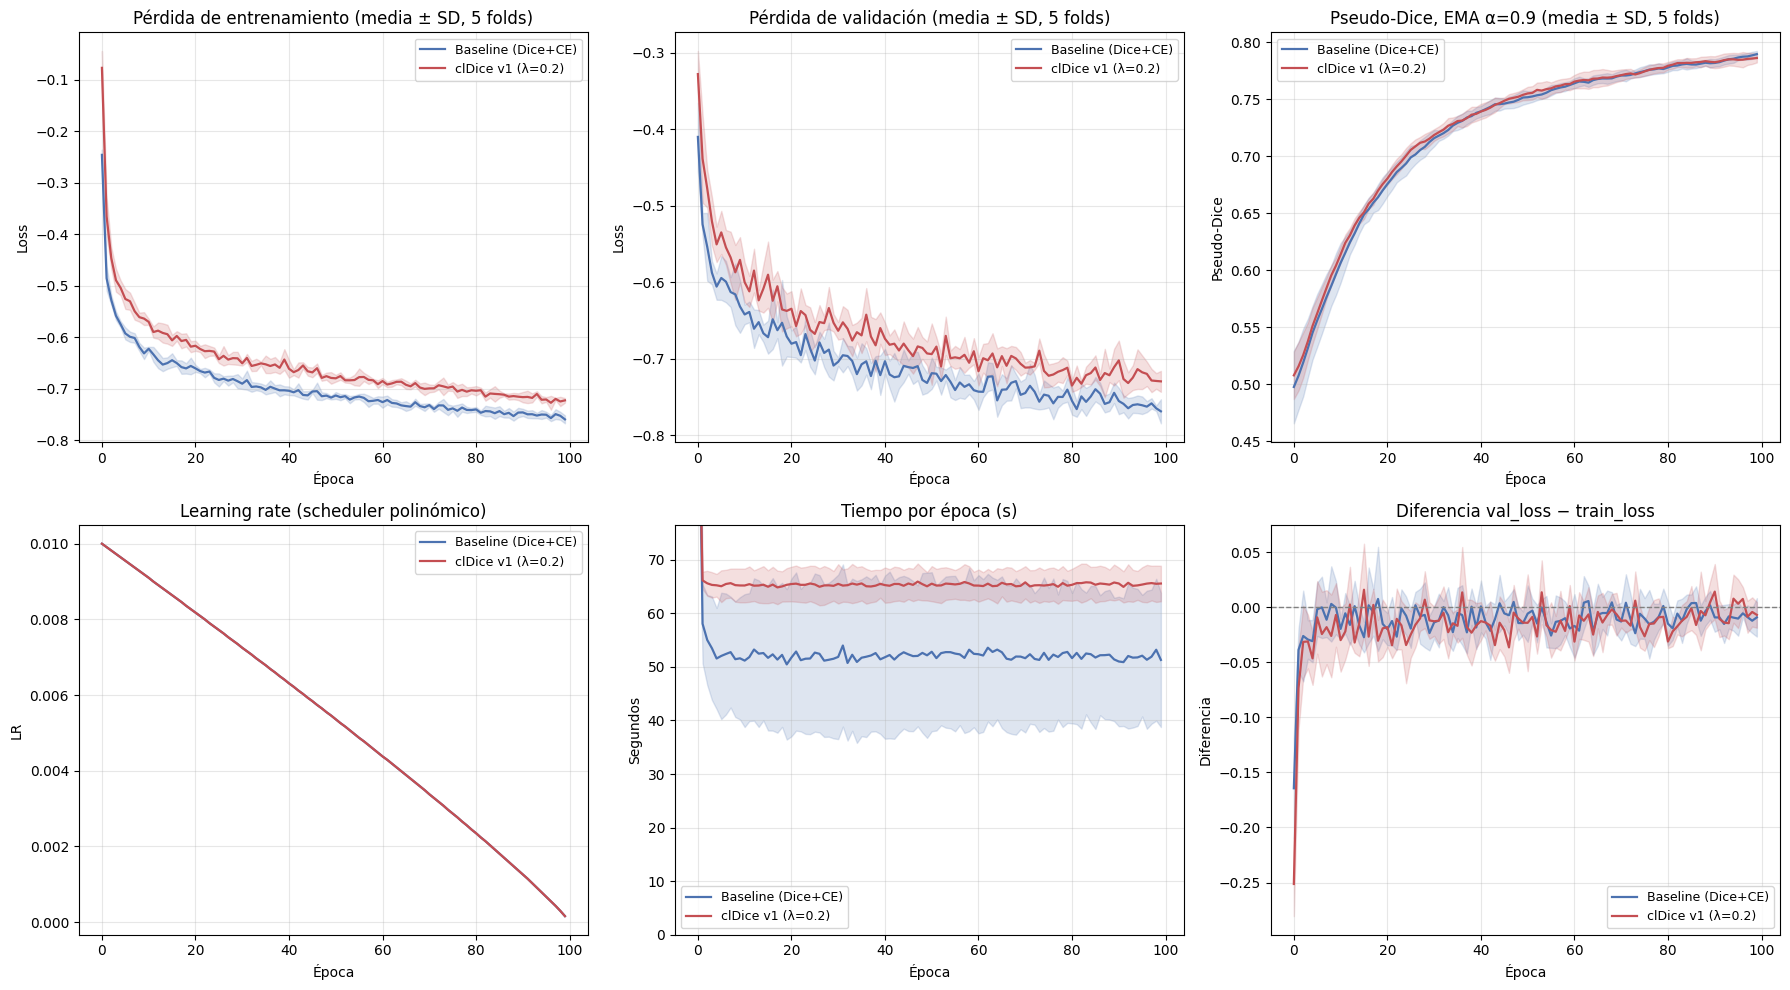

In [5]:
def ema(x, a=0.9):
    out, prev = [], None
    for v in x:
        prev = v if prev is None else a*prev + (1-a)*v
        out.append(prev)
    return np.array(out)

data["pseudo_dice_ema"] = data.groupby(["config", "fold"])["pseudo_dice"].transform(lambda s: pd.Series(ema(s.values), index=s.index))

def panel(ax, col, title, ylabel):
    for label in TRAINERS:
        sub = data[data.config == label].pivot(index="epoch", columns="fold", values=col)
        m, s = sub.mean(axis=1), sub.std(axis=1)
        ax.plot(m.index, m, color=COLORS[label], label=label, lw=1.6)
        ax.fill_between(m.index, m - s, m + s, color=COLORS[label], alpha=0.18)
    ax.set_title(title); ax.set_xlabel("Época"); ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3); ax.legend(fontsize=9)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
panel(axes[0,0], "train_loss", "Pérdida de entrenamiento (media ± SD, 5 folds)", "Loss")
panel(axes[0,1], "val_loss", "Pérdida de validación (media ± SD, 5 folds)", "Loss")
panel(axes[0,2], "pseudo_dice_ema", "Pseudo-Dice, EMA α=0.9 (media ± SD, 5 folds)", "Pseudo-Dice")
panel(axes[1,0], "lr", "Learning rate (scheduler polinómico)", "LR")
panel(axes[1,1], "epoch_time_s", "Tiempo por época (s)", "Segundos")
axes[1,1].set_ylim(0, data["epoch_time_s"].quantile(0.99) * 1.1)
panel(axes[1,2], "gap_val_train", "Diferencia val_loss − train_loss", "Diferencia")
axes[1,2].axhline(0, color="gray", ls="--", lw=1)
plt.tight_layout()
plt.savefig(BASE / "curvas_5folds_media_sd.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Curvas de cada fold por separado

Permiten comprobar que el comportamiento observado en la media no procede de un único fold.


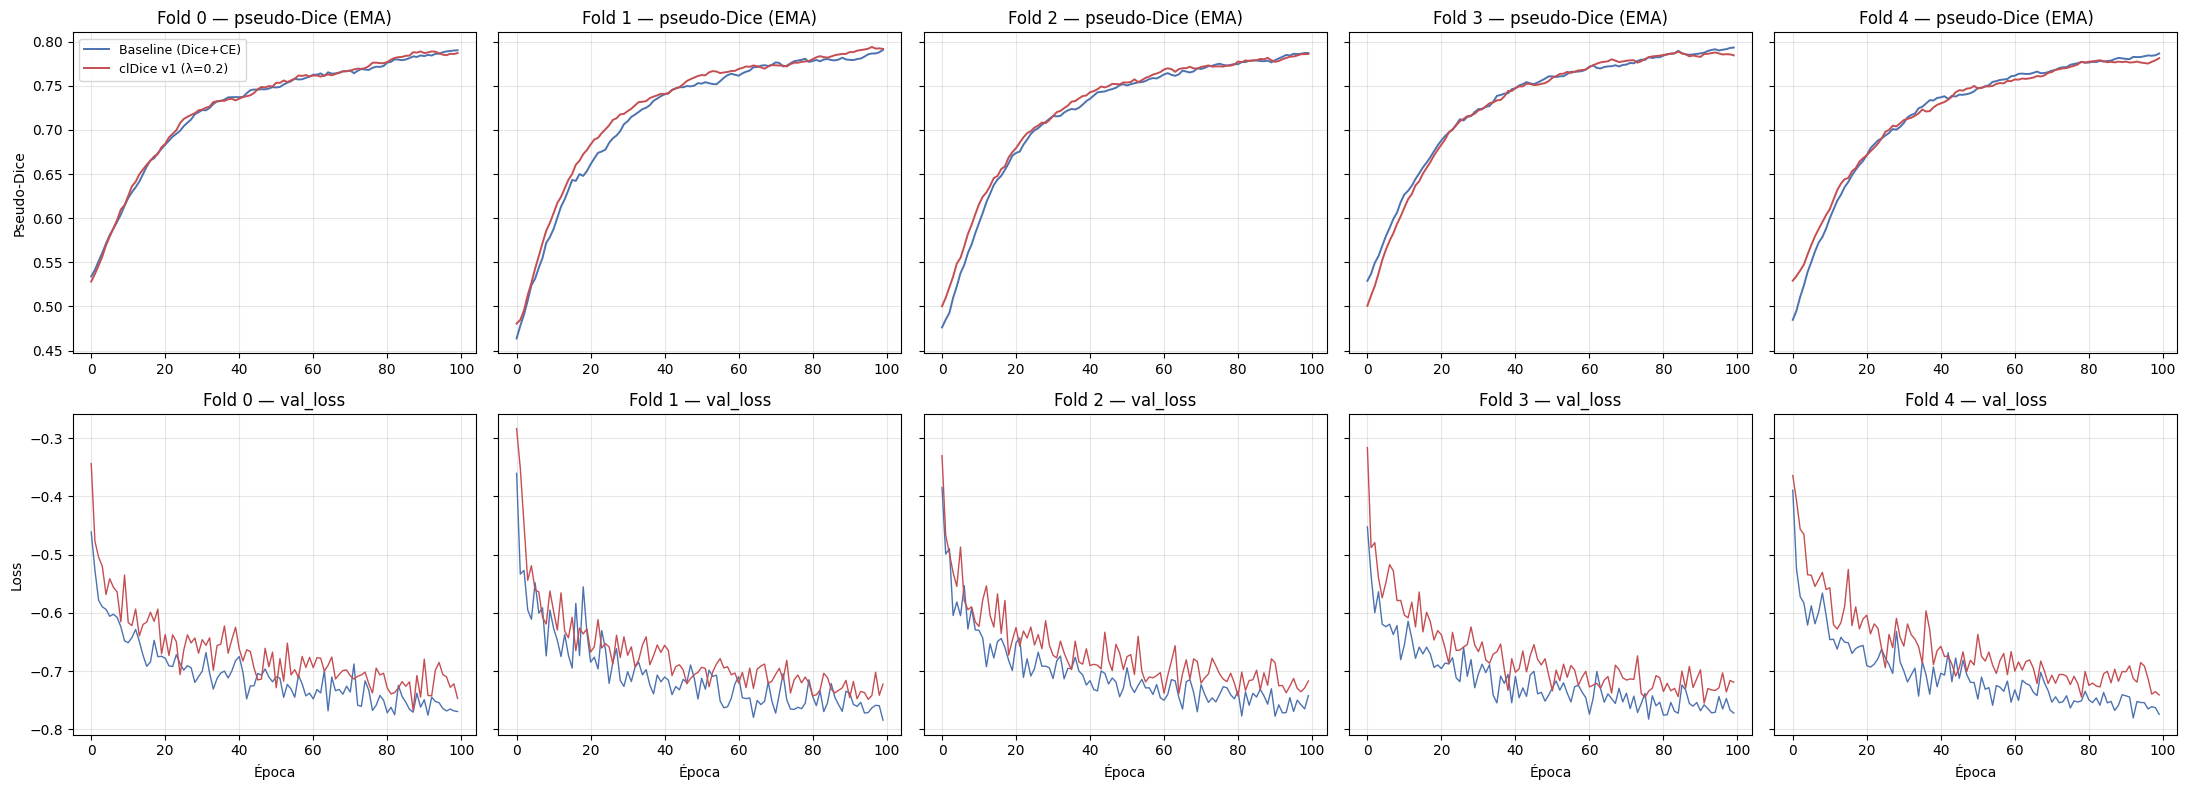

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8), sharey="row")
for k in FOLDS:
    for label in TRAINERS:
        sub = data[(data.config == label) & (data.fold == k)]
        axes[0, k].plot(sub["epoch"], sub["pseudo_dice_ema"], color=COLORS[label], label=label, lw=1.4)
        axes[1, k].plot(sub["epoch"], sub["val_loss"], color=COLORS[label], label=label, lw=1.0)
    axes[0, k].set_title(f"Fold {k} — pseudo-Dice (EMA)"); axes[1, k].set_title(f"Fold {k} — val_loss")
    axes[1, k].set_xlabel("Época")
    for r in (0, 1): axes[r, k].grid(alpha=0.3)
axes[0, 0].set_ylabel("Pseudo-Dice"); axes[1, 0].set_ylabel("Loss"); axes[0, 0].legend(fontsize=9)
plt.tight_layout()
plt.savefig(BASE / "curvas_5folds_por_fold.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Resumen numérico


In [7]:
rows = []
for (label, k), g in data.groupby(["config", "fold"]):
    g = g.sort_values("epoch")
    rows.append({
        "config": label, "fold": k,
        "pseudo_dice_ult5": g["pseudo_dice"].iloc[-5:].mean(),
        "pseudo_dice_ema_final": g["pseudo_dice_ema"].iloc[-1],
        "val_loss_ult5": g["val_loss"].iloc[-5:].mean(),
        "tiempo_total_h": g["epoch_time_s"].sum() / 3600,
        "tiempo_medio_epoca_s": g["epoch_time_s"].mean(),
    })
res = pd.DataFrame(rows).round(4)
res.to_csv(BASE / "curvas_5folds_resumen.csv", index=False)
display(res)
display(res.groupby("config")[["pseudo_dice_ult5", "val_loss_ult5", "tiempo_total_h", "tiempo_medio_epoca_s"]].agg(["mean", "std"]).round(4))

,config,fold,pseudo_dice_ult5,pseudo_dice_ema_final,val_loss_ult5,tiempo_total_h,tiempo_medio_epoca_s
0,Baseline (Dice+CE),0,0.7964,0.7904,-0.7671,1.0964,39.4703
1,Baseline (Dice+CE),1,0.8014,0.7908,-0.7673,1.0500,37.8014
2,Baseline (Dice+CE),2,0.7918,0.7873,-0.7568,1.7610,63.3953
3,Baseline (Dice+CE),3,0.7954,0.7935,-0.7590,1.7089,61.5210
4,Baseline (Dice+CE),4,0.7919,0.7867,-0.7635,1.7228,62.0214
5,clDice v1 (λ=0.2),0,0.7864,0.7873,-0.7225,1.7641,63.5071
6,clDice v1 (λ=0.2),1,0.7938,0.7920,-0.7313,1.7196,61.9071
7,clDice v1 (λ=0.2),2,0.7908,0.7862,-0.7248,1.8955,68.2395
8,clDice v1 (λ=0.2),3,0.7798,0.7846,-0.7205,1.8766,67.5575
9,clDice v1 (λ=0.2),4,0.7867,0.7814,-0.7240,1.8831,67.7932


pseudo_dice_ult5         val_loss_ult5          \
                               mean     std          mean     std   
config                                                              
Baseline (Dice+CE)           0.7954  0.0039       -0.7627  0.0047   
clDice v1 (λ=0.2)            0.7875  0.0053       -0.7246  0.0041   

                   tiempo_total_h         tiempo_medio_epoca_s           
                             mean     std                 mean      std  
config                                                                   
Baseline (Dice+CE)         1.4678  0.3611              52.8419  12.9998  
clDice v1 (λ=0.2)          1.8278  0.0803              65.8009   2.8907

## 6. Nota metodológica

El pseudo-Dice es una estimación rápida que nnU-Net calcula durante el entrenamiento sobre parches de validación, sin reconstruir el volumen completo ni aplicar post-procesado. Las curvas permiten verificar que el entrenamiento converge de forma estable y sin sobreajuste evidente; la comparación entre configuraciones se basa en las métricas calculadas sobre el volumen completo (notebook 34). Las pérdidas de v1 incluyen el término de soft-clDice, por lo que sus valores absolutos no son comparables con los del baseline.

El tiempo por época de la primera iteración incluye la compilación y la carga inicial, y suele ser claramente superior al resto.
